<a href="https://colab.research.google.com/github/alexmando/NeuroSymbolic_CardGame/blob/main/Neurosymbolic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🃏 Neuro-Symbolic AI Project: Card Suit Game (DeepProbLog vs. Neural Baseline)

This notebook contains the implementation, training, and evaluation of the project for the **Neuro-Symbolic AI** course.

The project addresses a classification and reasoning problem based on a simplified card game where two players each play a card and the outcome depends exclusively on their suits (*Hearts, Clubs, Spades*), ignoring numerical ranks and face cards, following a circular logic[cite: 4]:
* **Hearts** > **Clubs**[cite: 4]
* **Clubs** > **Spades**[cite: 4]
* **Spades** > **Hearts**[cite: 4]
* Same suit = **Draw**[cite: 4]

---

## 🏗️ Objectives and Architectures Compared
The project requires developing and comparing two different Artificial Intelligence paradigms:
1. **Approach A (DeepProbLog):** A Neuro-Symbolic system where a neural component (CNN) handles visual perception (producing probability distributions over individual card suits), while a probabilistic logic engine applies formal game rules to deduce the outcome.
2. **Approach B (Neural Baseline):** A purely sub-symbolic system (Siamese Network) that takes the pair of images as input and directly predicts the game outcome via end-to-end learning, without explicit rule knowledge.

---

## 📂 Data Preparation Methodology (The Manifest Strategy)
To ensure scientific rigor and a perfectly fair comparison between the two approaches (particularly for the **Data Efficiency** experiment required by the assignment, which evaluates models on 20%, 50%, and 100% of the data)[cite: 4]:
* **Dataset Filtering:** The base dataset (*Cards Image Dataset-Classification* from Kaggle) was filtered by removing Diamonds and Jokers, aggregating cards solely by suit[cite: 4].
* **Fixed Manifests:** Image pairs ($I_1, I_2$) and their corresponding outcomes were generated offline via a deterministic script (fixing a random seed) and saved into structured CSV files (`train_100.csv`, `train_50.csv`, `train_20.csv`, `test.csv`).
* **Strict Rule:** All model DataLoaders exclusively use these Manifest files to load data, ensuring that both the Baseline and DeepProbLog are trained and tested on the exact same card matches[cite: 4].

In [ ]:
!pip install kagglehub pandas scikit-learn

import kagglehub
import os
import shutil
import random
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

# 1. DOWNLOAD DEL DATASET
print("Download del dataset Kaggle in corso...")
dataset_path = kagglehub.dataset_download("gpiosenka/cards-image-datasetclassification")
output_dir = Path('/content/cards_filtered')
print(f"Dataset originale scaricato in: {dataset_path}")

# 2. PULIZIA E FILTRAGGIO (Cuori, Fiori, Picche)
allowed_suits = {'hearts': 'hearts', 'clubs': 'clubs', 'spades': 'spades'}

for split in ['train', 'test']:
    split_src = Path(dataset_path) / split
    split_dst = output_dir / split

    if not split_src.exists(): continue

    for suit in allowed_suits.keys():
        (split_dst / suit).mkdir(parents=True, exist_ok=True)

    for card_folder in split_src.iterdir():
        if not card_folder.is_dir(): continue
        folder_name = card_folder.name.lower()

        # Regola traccia: Escludere Diamonds e Joker
        if 'joker' in folder_name or 'diamonds' in folder_name: continue

        target_suit = next((suit for suit in allowed_suits if suit in folder_name), None)
        if target_suit:
            for img_file in card_folder.glob('*.jpg'):
                dst_file = split_dst / target_suit / f"{card_folder.name}_{img_file.name}"
                shutil.copy(img_file, dst_file)

print(f"Immagini pulite salvate in: {output_dir}")

# 3. GENERAZIONE DELLE COPPIE (MANIFEST)
def determine_outcome(suit1, suit2):
    # Regole del professore: Hearts > Clubs, Clubs > Spades, Spades > Hearts, Stesso = Draw
    if suit1 == suit2: return 'draw', 2
    if (suit1 == 'hearts' and suit2 == 'clubs') or \
       (suit1 == 'clubs' and suit2 == 'spades') or \
       (suit1 == 'spades' and suit2 == 'hearts'):
        return 'player1', 0
    return 'player2', 1

def create_pairs(split_dir, num_pairs=2000):
    suits = ['hearts', 'clubs', 'spades']
    images = {s: list(Path(split_dir / s).glob('*.jpg')) for s in suits}

    random.seed(42) # FONDAMENTALE per generare sempre le stesse coppie
    pairs = []

    for _ in range(num_pairs):
        s1, s2 = random.choice(suits), random.choice(suits)
        img1, img2 = random.choice(images[s1]), random.choice(images[s2])
        out_str, out_num = determine_outcome(s1, s2)
        pairs.append({
            'img1_path': str(img1),
            'img2_path': str(img2),
            'suit1': s1, 'suit2': s2,
            'outcome_str': out_str, 'label': out_num
        })
    return pd.DataFrame(pairs)

# Creiamo 3000 coppie di addestramento e 1000 di test
df_train_full = create_pairs(output_dir / 'train', num_pairs=3000)
df_test = create_pairs(output_dir / 'test', num_pairs=1000)

# 4. CREAZIONE DEI SUBSET PER LA "DATA EFFICIENCY" (Traccia: 20%, 50%, 100%)
# Fissiamo random_state per mantenere inalterati i set (Traccia: "keeping validation and test data unchanged")
df_train_50, _ = train_test_split(df_train_full, train_size=0.5, random_state=42, stratify=df_train_full['label'])
df_train_20, _ = train_test_split(df_train_full, train_size=0.2, random_state=42, stratify=df_train_full['label'])

# 5. SALVATAGGIO DEI CSV
csv_dir = Path('/content/manifests')
csv_dir.mkdir(exist_ok=True)

df_train_full.to_csv(csv_dir / 'train_100.csv', index=False)
df_train_50.to_csv(csv_dir / 'train_50.csv', index=False)
df_train_20.to_csv(csv_dir / 'train_20.csv', index=False)
df_test.to_csv(csv_dir / 'test.csv', index=False)

print("\n--- OPERAZIONE COMPLETATA! ---")
print(f"File Train 100%: {len(df_train_full)} righe")
print(f"File Train 50%: {len(df_train_50)} righe")
print(f"File Train 20%: {len(df_train_20)} righe")
print(f"File Test: {len(df_test)} righe")
print(f"I tuoi 4 file CSV sono nella cartella: {csv_dir}")

Download del dataset Kaggle in corso...
Using Colab cache for faster access to the 'cards-image-datasetclassification' dataset.
Dataset originale scaricato in: /kaggle/input/cards-image-datasetclassification
Immagini pulite salvate in: /content/cards_filtered

--- OPERAZIONE COMPLETATA! ---
File Train 100%: 3000 righe
File Train 50%: 1500 righe
File Train 20%: 600 righe
File Test: 1000 righe
I tuoi 4 file CSV sono nella cartella: /content/manifests


### 📊 Data Exploration & Class Balance Verification
This code cell loads the generated training manifest (`train_100.csv`) and performs exploratory data analysis to verify dataset integrity. It checks the class balance across outcomes (`player1`, `player2`, `draw`) via a bar plot and visually inspects a random sample of card pairs along with their computed game rules to ensure correctness before training.

--- DATA EXPLORATION: CARD DUEL DATASET ---
Totale partite generate: 3000

Distribuzione delle classi:
outcome_str
draw       1060
player2     978
player1     962
Name: count, dtype: int64


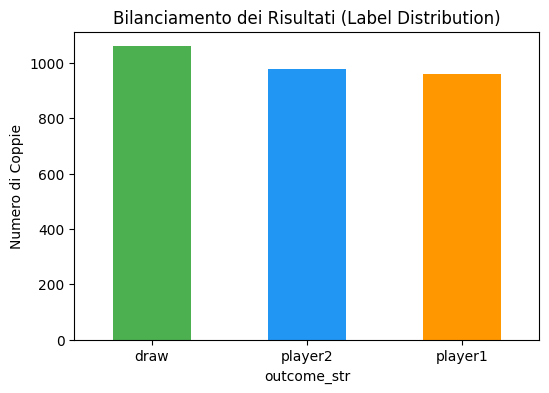

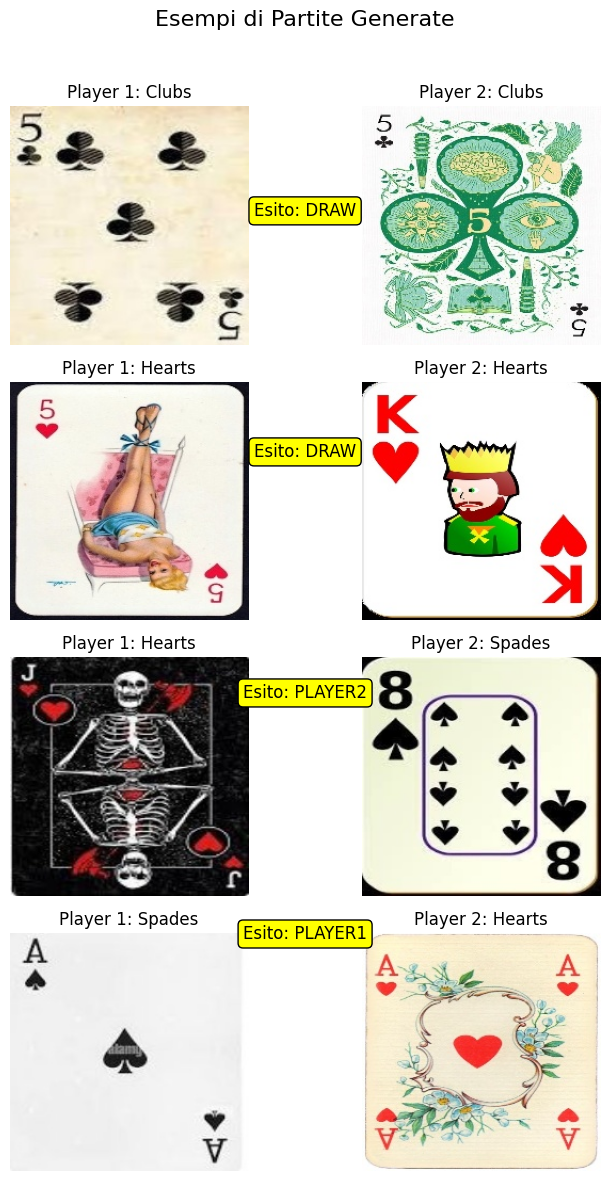

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import random
from pathlib import Path

# 1. Caricamento del Manifest principale
csv_path = '/content/manifests/train_100.csv'
df = pd.read_csv(csv_path)

print("--- DATA EXPLORATION: CARD DUEL DATASET ---")
print(f"Totale partite generate: {len(df)}")

# 2. Controllo del Bilanciamento delle Classi
class_counts = df['outcome_str'].value_counts()
print("\nDistribuzione delle classi:")
print(class_counts)

fig, ax = plt.subplots(figsize=(6, 4))
class_counts.plot(kind='bar', color=['#4CAF50', '#2196F3', '#FF9800'], ax=ax)
ax.set_title("Bilanciamento dei Risultati (Label Distribution)")
ax.set_ylabel("Numero di Coppie")
ax.set_xticklabels(class_counts.index, rotation=0)
plt.show()

# 3. Visualizzazione di un campione di "Partite" (Immagini reali)
def show_sample_matches(dataframe, num_samples=4):
    # Peschiamo righe a caso dal manifest
    sample_df = dataframe.sample(n=num_samples, random_state=42).reset_index(drop=True)

    fig, axes = plt.subplots(num_samples, 2, figsize=(8, 3 * num_samples))
    fig.suptitle("Esempi di Partite Generate", fontsize=16)

    for i in range(num_samples):
        row = sample_df.iloc[i]

        img1 = Image.open(row['img1_path'])
        img2 = Image.open(row['img2_path'])

        # Plot Carta 1 (Player 1)
        axes[i, 0].imshow(img1)
        axes[i, 0].set_title(f"Player 1: {row['suit1'].capitalize()}")
        axes[i, 0].axis('off')

        # Plot Carta 2 (Player 2)
        axes[i, 1].imshow(img2)
        axes[i, 1].set_title(f"Player 2: {row['suit2'].capitalize()}")
        axes[i, 1].axis('off')

        # Aggiungiamo un testo in mezzo per dire chi vince
        fig.text(0.5, axes[i,0].get_position().y0 + 0.1,
                 f"Esito: {row['outcome_str'].upper()}",
                 ha="center", va="center", fontsize=12,
                 bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="yellow"))

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# Mostriamo le carte!
show_sample_matches(df, num_samples=4)